# Plot results from test_methods.py

The results are stored in a DataFrame with the following columns:
- method: Source reconstruction method
- region: Region onset of spike source
- half: EEG peak half rising time
- peak: EEG peak time

The following columns shows the correlation achieved by the method over multiple time points. <br>

## 📦 Imports

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `corrs`: Source reconstruction correlations over time.

In [32]:
select_methods = [
    "cset",
    "sloreta",
    "wcset",
]

results = pd.read_csv("test_methods.csv")
results = results[results["method"].isin(select_methods)]
print(results.shape)
results.head(3)

(99000, 6)


,timepoint,correlation,method,region,half,peak
0,0.500,0.000000,cset,ctx-lh-precentral_1,False,False
1,0.504,0.025445,cset,ctx-lh-precentral_1,False,False
2,0.508,0.039083,cset,ctx-lh-precentral_1,False,False


#### ⚙️ **<font color=green>Plot correlation at half rising phase and peak phase</font>**

<Axes: xlabel='peak', ylabel='correlation'>

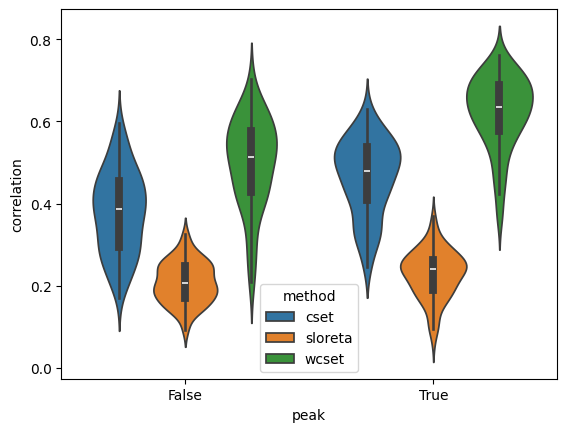

In [33]:
points = results[results["half"] | results["peak"]]
points = points.groupby(["method", "region", "half", "peak"]).mean()

sns.violinplot(data=points, x="peak", y="correlation", hue="method")

#### ⚙️ **<font color=green>Plot correlation over time</font>**

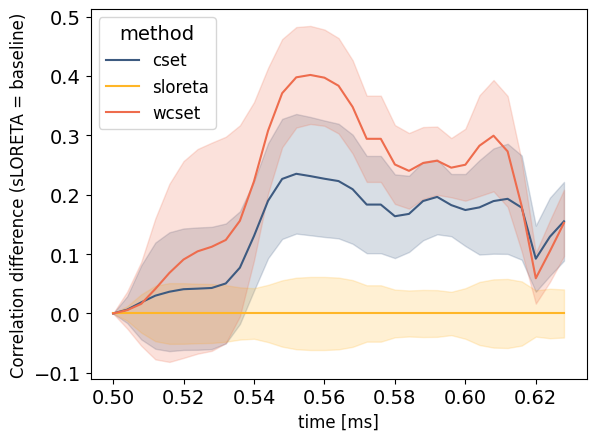

In [34]:
ts = results.drop(["half", "peak"], axis=1)
ts = ts.groupby(["method", "region", "timepoint"]).mean().reset_index()

# subtract sloreta mean
baseline_mean = ts[ts["method"] == "sloreta"].groupby("timepoint")["correlation"].mean().reset_index()
baseline_mean = baseline_mean.rename(columns={"correlation": "baseline_mean_correlation"})

ts_merged = ts.merge(baseline_mean, on="timepoint", how="left")
ts_merged["difference_from_baseline"] = ts_merged["correlation"] - ts_merged["baseline_mean_correlation"]

colors = [
    "#3d5a80",
    "#ffb627",
    "#ee6c4d",
]

ax = sns.lineplot(data=ts_merged, x="timepoint", y="difference_from_baseline", hue="method", palette=colors, errorbar=("sd", 1))
ax.set_xlabel("time [ms]", fontsize=12)
ax.set_ylabel("Correlation difference (sLORETA = baseline)", fontsize=12)
ax.tick_params(labelsize=14)
plt.legend(title = "method", fontsize='12', title_fontsize='14')

# Plot results from test_sabotage.py

The results are stored in a DataFrame with the following columns:
- subject: Template subject
- method: Source reconstruction method
- region: Region onset of spike source
- correlation: Correlation at peak time

## 📦 Imports

In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `sabotage`: Source reconstruction correlations for various degrees of connectome sabotaging

In [36]:
sabotage = pd.read_csv("sabotage.csv")
print(sabotage.shape)
sabotage = sabotage[sabotage["method"].isin(["cset", "sloreta", "geometry", "template"])]
sabotage.head(3)

(15000, 5)


,subject,method,location,correlation,sabotage
0,vepcon_sub-10,geometry,ctx-rh-precentral_14,0.365505,0.0
1,vepcon_sub-10,template,ctx-rh-precentral_14,0.330471,0.0
2,vepcon_sub-10,sloreta,ctx-rh-precentral_14,0.174292,0.0


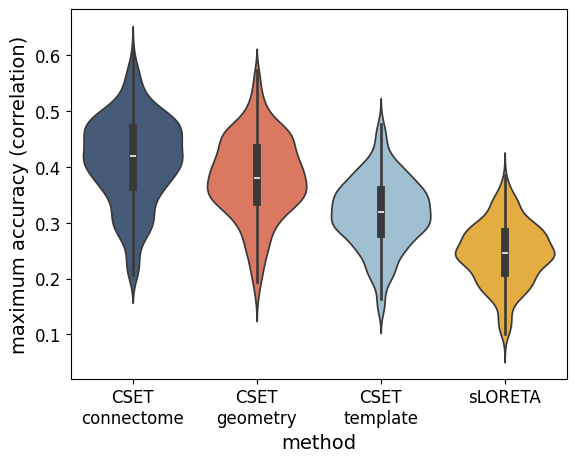

In [46]:
df = sabotage[sabotage["sabotage"]==0]
ax = sns.violinplot(df, x="method", y="correlation", hue="method", order=["cset", "geometry", "template", "sloreta"], palette=["#ee6c4d", "#98c1d9",  "#ffb627", "#3d5a80",])
ax.set_xlabel("method", fontsize=14)
ax.set_ylabel("maximum accuracy (correlation)", fontsize=14)
ax.set_xticks(ticks=[0,1,2,3], labels=["CSET\nconnectome", "CSET\ngeometry", "CSET\ntemplate", "sLORETA"])
ax.tick_params(labelsize=12)

In [51]:
df[df["method"]=="sloreta"]["correlation"].mean()

np.float64(0.24507650518462487)

/tmp/ipykernel_24800/2638416165.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sabotage"] = df["sabotage"]*100


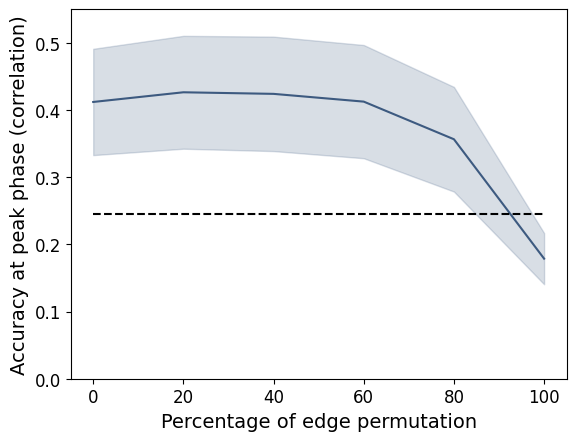

In [58]:
df = sabotage[sabotage["method"]=="cset"]
df["sabotage"] = df["sabotage"]*100
ax = sns.lineplot(df, x="sabotage", y="correlation", color="#3d5a80", errorbar=("sd", 1))
ax.set_ylabel("Accuracy at peak phase (correlation)", fontsize=14)
ax.set_xlabel("Percentage of edge permutation", fontsize=14)
ax.tick_params(labelsize=12)
ax.set(ylim=(0,0.55))
ax.hlines(y=0.245, xmin=0, xmax=100, color="black", linestyles="--")

<Axes: xlabel='sabotage', ylabel='correlation'>

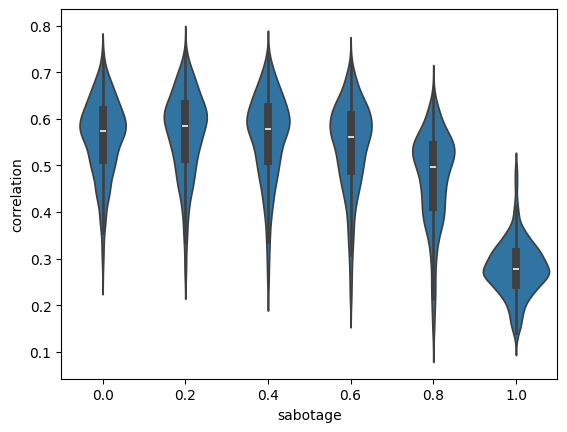

In [9]:
df = sabotage[sabotage["method"]=="wcset"]
sns.violinplot(df, x="sabotage", y="correlation")